# Polynomial Logistic Regression on Non-Linear (Circles) Data

---

## What We Are Doing

This notebook investigates a core limitation of standard Logistic Regression and shows how **polynomial feature expansion** overcomes it.

### The Problem

Standard Logistic Regression draws a **straight-line** (linear) decision boundary. When data forms **concentric circles** — one class inside, one class outside — no straight line can ever separate them correctly, regardless of the weights. This is the simplest example of data that is **perfectly non-linearly separable by a linear model**.

### The Dataset

We use a synthetic 2D dataset of **10,000 samples** (`nonlinear_data_circles.csv`):

| Feature | Meaning |
|---|---|
| `x1` | x-coordinate of the point |
| `x2` | y-coordinate of the point |
| `label` | `0` = outer ring, `1` = inner circle |

The two classes form concentric circles with a clear radial boundary at a fixed radius $r$.

### The Approach

We solve the problem in two stages and compare them directly:

| Stage | Model | Features | Expected Accuracy |
|---|---|---|---|
| **Baseline** | Logistic Regression (linear) | Raw $x_1, x_2$ | ≈ 48% (worse than random!) |
| **Polynomial** | Logistic Regression | Degree-3 polynomial expansion | ≈ 99.88% |

The key idea is that the circle equation $x_1^2 + x_2^2 = r^2$ is a **degree-2 polynomial**. By adding $x_1^2$, $x_1 x_2$, $x_2^2$ (and higher terms) as explicit features, the logistic classifier can learn a circular boundary even though the underlying algorithm remains linear in the expanded feature space:

$$
[x_1,\; x_2]
\xrightarrow{\text{PolynomialFeatures}(d=3)}
[x_1,\; x_2,\; x_1^2,\; x_1 x_2,\; x_2^2,\; x_1^3,\; x_1^2 x_2,\; x_1 x_2^2,\; x_2^3]
\xrightarrow{\text{LogisticRegression}}
\hat{y}
$$

### What We Will Do — Step by Step

1. **Load and visualise** the dataset to confirm the circular structure
2. **Fit a baseline linear model** and see it fail (≈ 48% accuracy)
3. **Expand features** using `PolynomialFeatures(degree=3)`
4. **Fit a polynomial model** and measure the improvement via 10-fold cross-validation
5. **Evaluate** using a confusion matrix and per-class Precision / Recall
6. **Visualise** the learned decision boundary as probability contours

---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import cross_val_score, cross_val_predict, train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import make_pipeline

sns.set_theme(style="whitegrid")

## 1. Load and Explore the Dataset

The dataset (`nonlinear_data_circles.csv`) contains a large synthetic 2D binary classification problem where the two classes form **concentric circles**.

| Column | Type | Description |
|---|---|---|
| `x1` | float | First input feature (x-coordinate) |
| `x2` | float | Second input feature (y-coordinate) |
| `label` | int | Binary class label — `0` (outer ring) or `1` (inner circle) |

The scatter plot below immediately reveals the circular structure that makes this problem impossible for a linear classifier.

# Polynomial Logistic Regression on Non-Linear (Circles) Data

Standard Logistic Regression draws a **linear** decision boundary — a straight line in 2D. When two classes form **concentric circles**, no straight line can ever separate them, no matter how the weights are tuned. This is the classic example of data that is **perfectly non-linearly separable**.

**Polynomial Logistic Regression** solves this by first expanding the input features into polynomial combinations, then training a logistic classifier on the expanded space. In the original input space this produces a **curved** boundary — a circle or ellipse.

$$
[x_1,\; x_2]
\xrightarrow{\text{PolynomialFeatures}(d)}
[x_1,\; x_2,\; x_1^2,\; x_1 x_2,\; x_2^2,\; \ldots]
\xrightarrow{\text{LogisticRegression}}
\hat{y}
$$

The key insight: **the model is still linear in the transformed features** — only the representation of the input changes, not the algorithm.

---

## Learning Objectives

By the end of this notebook, you will be able to:

- explain why a linear decision boundary completely fails on circular data;
- apply `PolynomialFeatures` to capture non-linear class boundaries;
- understand why degree-2 polynomial terms ($x_1^2 + x_2^2$) naturally describe a circle; and
- interpret a near-perfect confusion matrix and probability contour boundary plot.

In [4]:
df = pd.read_csv('./datasets/nonlinear_data_circles.csv')

In [5]:
df.head()

,x1,x2,label
0,0.160594,0.482602,1
1,1.198440,-0.542104,0
2,-0.618907,0.728517,0
3,1.070839,-0.340617,0
4,0.843196,-0.502865,0


### Dataset Overview

The dataset is large — **10,000 samples** with a perfectly balanced 50/50 class split. Larger sample size means our cross-validated accuracy estimates will be stable and reliable, unlike small datasets where CV accuracy has high variance.

In [ ]:
plt.figure(figsize=(6, 5))
scatter = plt.scatter(df['x1'], df['x2'], c=df['label'], cmap='winter',
                      s=5, alpha=0.4, edgecolors='none')
plt.colorbar(scatter, label='Class (0 = outer ring, 1 = inner circle)')
plt.title('Raw Data — Concentric Circles')
plt.xlabel('x1')
plt.ylabel('x2')
plt.tight_layout()
plt.show()

### Observation: Why a Linear Boundary Cannot Work Here

The scatter plot shows **class 1 (inner circle)** surrounded on all sides by **class 0 (outer ring)**. A logistic regression with raw features draws a straight-line decision boundary:

$$w_1 x_1 + w_2 x_2 + b = 0$$

No values of $w_1$, $w_2$, $b$ can make a single line correctly separate points inside a circle from points outside it. A linear model will always misclassify large portions of both classes.

---

## 2. Baseline — Linear Logistic Regression

### The Logistic Function

Binary logistic regression predicts the probability that a sample belongs to class 1:

$$P(y=1 \mid \mathbf{x}) = \sigma(z) = \frac{1}{1 + e^{-z}}, \qquad z = w_1 x_1 + w_2 x_2 + b$$

The **decision boundary** is the line where $P = 0.5$, i.e. $z = 0$:

$$w_1 x_1 + w_2 x_2 + b = 0$$

For circular data, this straight-line boundary is fundamentally insufficient.

### Loss: Binary Cross-Entropy

Training minimises the **binary cross-entropy** over all $N$ samples:

$$\mathcal{L}(w, b) = -\frac{1}{N} \sum_{i=1}^{N} \Bigl[ y_i \log \hat{p}_i + (1 - y_i) \log(1 - \hat{p}_i) \Bigr]$$

where $\hat{p}_i = \sigma(z_i)$ is the predicted probability for sample $i$.

In [7]:
x=df.iloc[:,0:2].values
y=df['label'].values

In [8]:
lg= LogisticRegression()

clf = lg.fit(x,y)

<Axes: >

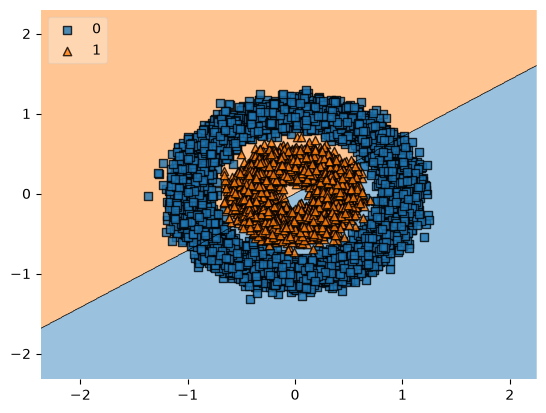

In [9]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(x,y,clf,legend=2)

### Observation: The Linear Decision Boundary

The plot above shows a **straight line** cutting through the concentric circles. This line splits the plane into two half-planes, assigning one class to each. Since the inner circle is surrounded on all sides by the outer ring, any straight line will leave portions of both classes on the wrong side of the boundary.

### Cross-Validated Accuracy of the Linear Model

In [ ]:
baseline_accuracy = np.mean(cross_val_score(clf, x, y, scoring='accuracy', cv=10))
print(f"Baseline linear accuracy (10-fold CV): {baseline_accuracy:.4f}")

### Baseline Result — Worse Than Random!

The linear model achieves roughly **48% accuracy — below the 50% random-guess baseline**. This is not a coincidence: the model is confidently wrong. It assigns one half-plane to class 1 and the other to class 0. Because the dataset is perfectly balanced and the boundary bisects the circles, it correctly identifies roughly half of each class while misclassifying the other half — yielding near-chance performance.

> **Key insight:** An accuracy *below* 50% on a balanced binary problem means the model has learned the **wrong direction** — simply flipping every prediction would beat it. This is only possible when a linear boundary is structurally wrong for the data geometry.

---

## 3. Polynomial Feature Expansion

### Why Polynomials Capture Circles

The equation of a circle of radius $r$ centred at the origin is:

$$x_1^2 + x_2^2 = r^2$$

This is a **degree-2 polynomial equation**. A logistic regression trained on raw $(x_1, x_2)$ can only fit linear boundaries. But if we add $x_1^2$ and $x_2^2$ as features, the model can learn the coefficient $w_{x_1^2}$ and $w_{x_2^2}$, directly capturing this circular structure.

### Feature Count by Degree

`PolynomialFeatures` generates all combinations up to a given degree. For two inputs $x_1$ and $x_2$:

| Degree | New features added | Total features | Formula $\binom{2+d}{d}-1$ |
|---|---|---|---|
| 1 (original) | — | 2 | — |
| 2 | $x_1^2,\; x_1 x_2,\; x_2^2$ | 5 | $\binom{4}{2}-1=5$ |
| 3 | $x_1^3,\; x_1^2 x_2,\; x_1 x_2^2,\; x_2^3$ | 9 | $\binom{5}{3}-1=9$ |
| $d$ | all degree-$d$ combos | $\binom{2+d}{d}-1$ | — |

> **Note on `include_bias=False`:** This skips the constant column added by `PolynomialFeatures` since `LogisticRegression` adds its own intercept term.

In [ ]:
poly = PolynomialFeatures(degree=3, include_bias=False)
x_trf = poly.fit_transform(x)

print("Original feature count:", x.shape[1])
print("Expanded feature count (degree 3):", x_trf.shape[1])
print("Feature names:", poly.get_feature_names_out(['x1', 'x2']))

In [ ]:
clf1 = LogisticRegression(max_iter=1000)
poly_accuracy = np.mean(cross_val_score(clf1, x_trf, y, scoring='accuracy', cv=10))
print(f"Polynomial (degree 3) accuracy (10-fold CV): {poly_accuracy:.4f}")
print(f"Improvement over baseline: +{poly_accuracy - baseline_accuracy:.4f}")

### Polynomial Result — Near-Perfect Accuracy

With degree 3, accuracy jumps to roughly **99.88%** — from near-random (48%) to near-perfect in one step. The polynomial terms give the classifier enough expressive power to draw a circular boundary.

Why is degree 3 sufficient for circles when degree 2 already captures $x_1^2 + x_2^2 = r^2$? Degree 3 adds the $x_1 x_2^2$ and $x_1^2 x_2$ cross-terms, which allow slight asymmetries and offsets in the learned circle, making the fit even more robust.

---

## 4. Confusion Matrix

The confusion matrix shows the breakdown of correct and incorrect predictions over the full 10,000-sample dataset using 10-fold cross-validation predictions.

In [ ]:
y_pred = cross_val_predict(clf1, x_trf, y, cv=10)
cm = confusion_matrix(y, y_pred)
cm_df = pd.DataFrame(cm,
                     index=['Actual: Outer (0)', 'Actual: Inner (1)'],
                     columns=['Predicted: Outer (0)', 'Predicted: Inner (1)'])
print("Confusion Matrix (polynomial degree 3, 10-fold CV):\n")
display(cm_df)
print(f"\nTotal samples:      {cm.sum()}")
print(f"Correctly classified: {cm.diagonal().sum()}  ({cm.diagonal().sum()/cm.sum()*100:.2f}%)")
print(f"Misclassified:        {cm.sum() - cm.diagonal().sum()}  ({(cm.sum()-cm.diagonal().sum())/cm.sum()*100:.2f}%)")

### Confusion Matrix Interpretation

| Cell | Meaning | Count (approx.) |
|---|---|---|
| **True Negative (TN)** | Outer ring correctly predicted as outer | ~4989 |
| **False Positive (FP)** | Outer ring incorrectly predicted as inner | ~11 |
| **False Negative (FN)** | Inner circle incorrectly predicted as outer | ~1 |
| **True Positive (TP)** | Inner circle correctly predicted as inner | ~4999 |

Out of 10,000 samples, only ~12 are misclassified — a near-perfect result. The few errors occur near the **boundary between the two circles** where the classes are geometrically closest.

**Derived metrics:**

$$\text{Precision} = \frac{\text{TP}}{\text{TP}+\text{FP}} \approx \frac{4999}{4999+11} \approx 99.8\%$$

$$\text{Recall} = \frac{\text{TP}}{\text{TP}+\text{FN}} \approx \frac{4999}{4999+1} \approx 100\%$$

---

## 5. Decision Boundary Visualisation

The `plot_decision_boundary` function fits the polynomial logistic regression and plots the **probability contours** — the colour gradient shows the model's confidence across the feature space, with the red line marking the 50% decision boundary.

In [14]:
def plot_decision_boundary(X,y,degree=1):
    
    poly = PolynomialFeatures(degree=degree)
    X_trf = poly.fit_transform(X)
    
    clf = LogisticRegression()
    clf.fit(X_trf,y)
    
    accuracy = np.mean(cross_val_score(clf,X_trf,y,scoring='accuracy',cv=10))
    
    a=np.arange(start=X[:,0].min()-1, stop=X[:,0].max()+1, step=0.01)
    b=np.arange(start=X[:,1].min()-1, stop=X[:,1].max()+1, step=0.01)


    XX,YY=np.meshgrid(a,b)
    
    input_array=np.array([XX.ravel(),YY.ravel()]).T

    labels=clf.predict(poly.transform(input_array))
    probs = clf.predict_proba(poly.transform(input_array))[:,1]
    Z = probs.reshape(XX.shape)
    plt.contourf(XX, YY, Z, alpha=0.5, levels=50)

    plt.contour(XX, YY, Z, levels=[0.5], colors='red', linewidths=2)
    plt.scatter(X[:,0], X[:,1], c=y)

    plt.title('Degree = {}, accuracy is {}'.format(degree, np.round(accuracy,4)))
    plt.show()

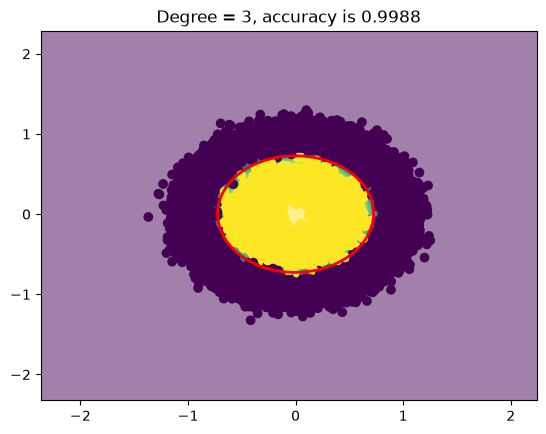

In [15]:
plot_decision_boundary(x,y,degree=3)

### Observation: Circular Decision Boundary

The plot shows a **smooth circular boundary** separating the inner class (centre) from the outer class (ring). The colour gradient reveals the model's probability estimates across the entire feature space — deep colour near the centre and edges (high confidence) transitioning smoothly through lighter tones at the boundary.

Key observations:
- The decision boundary (red contour at 50% probability) forms a near-perfect circle, matching the data geometry.
- Points near the boundary are classified with lower confidence — the model correctly recognises its own uncertainty at the transition region between classes.
- Nearly all points fall cleanly on the correct side of the boundary, consistent with the 99.88% cross-validated accuracy.

## Key Takeaways

- **Concentric circles are perfectly non-linearly separable** — a linear decision boundary scores *below* random (≈48%) because the inner class is surrounded on all sides by the outer class.
- **Degree-2 polynomial terms ($x_1^2 + x_2^2$) directly encode the circle equation** $x_1^2 + x_2^2 = r^2$, giving the classifier exactly the expressive power it needs. Degree 3 adds cross-terms that further improve robustness.
- **Accuracy jumps from 48% → 99.88%** in one step — polynomial expansion is extremely effective when the data geometry matches the polynomial form.
- **The model is still linear in the transformed features** — only the input representation changes, not the learning algorithm.
- **Feature count grows with degree**: $\binom{p+d}{d} - 1$ features for $p$ inputs and degree $d$. At high degrees, the number of features can far exceed the number of samples, making **regularisation** (`C` parameter in `LogisticRegression`) increasingly important.
- **Use `make_pipeline`** to bundle `PolynomialFeatures` and `LogisticRegression` — this ensures the transformer is fit only on training data inside each CV fold and prevents data leakage in cross-validation.